# FaceJPEG — كشف الوجوه المولّدة ودراسة أثر JPEG
## دفتر نهائي مستقل، الإصدار 2
الكود مضمن هنا؛ **لا تحتاج ZIP المشروع**. الإعداد الافتراضي Quick Test يختبر البرمجيات على40 شكلًا هندسيًا، وليس صور وجوه، ولا ينتج دقة علمية لكشف التوليد. بدّل إعداد `MODE` في المرحلة3 إلى `REAL` لتدريب بيانات الوجوه، ثم اختر مصدرها. لا توجد أوزان كشف وجوه حقيقية مضمّنة أو نتائج تدريب كامل مُدّعاة.

في أول تجربة شغّل **Runtime → Run all** بالإعدادات الافتراضية. للتدريب الحقيقي فعّل GPU من **Runtime → Change runtime type → GPU**، وحدّد البيانات واسم تجربة جديدًا في3 قبل Run all. ZIP البيانات يُرفع من أيقونة الملفات في Colab ويُكتب مساره؛ Google Drive يحتاج موافقتك على التركيب.

كل مرحلة تعرض تقدمها. `events.log` و`status.json` يسجلان المرحلة وآخر عملية وETA من القياسات؛ استمرار heartbeat يثبت أن المراقب حي فقط، ولا يثبت تقدم العداد أو سلامة كل عملية. لا توجد مهلة تلغي تدريبًا سليمًا. حدود القرار تختار من التحقق قبل فتح الاختبار، والدرجة ترجيح غير معاير وليست شهادة أصالة.

## 1 — تهيئة الكود وفحص بيئة التشغيل وGPU
تكتب هذه الخلية الكود المضمن في مجلد إصدار مستقل، وتحافظ على أي تغييرات محلية. ثم تفحص Torch/Torchvision وCUDA واسم البطاقة وذاكرتها. `+cpu` يصف بناء PyTorch؛ و`GPU=False` وحده لا يثبت سبب بطء جلسة سابقة. عند تغيير إصدار المشروع استخدم مجلدًا جديدًا بدل الكتابة فوق تعديلاتك.

In [1]:
import os, sys, json, gzip, base64, hashlib, importlib.util, subprocess, time
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
_blob = base64.b64decode('...')
assert hashlib.sha256(_blob).hexdigest() == 'c919e7aac443310db53ea288c34aee51091bf0d20d28081e3a45adf3d049401a', "Embedded source checksum failed"
_files = json.loads(gzip.decompress(_blob).decode("utf-8"))
_base = Path(os.environ.get("FACEJPEG_WORKSPACE", "/content" if IN_COLAB else str(Path.cwd())))
PROJECT = (_base / "facejpeg_final_v2").resolve()
PROJECT.mkdir(parents=True, exist_ok=True)
for _rel, _text in _files.items():
    _path = (PROJECT / _rel).resolve()
    if not _path.is_relative_to(PROJECT):
        raise ValueError("Unsafe source path")
    if _path.exists() and _path.read_text(encoding="utf-8") != _text:
        raise FileExistsError(f"{_path} has local changes: choose a new FACEJPEG_WORKSPACE or retain those changes")
    _path.parent.mkdir(parents=True, exist_ok=True)
    _path.write_text(_text, encoding="utf-8")
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT)) if str(PROJECT) not in sys.path else None
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT / ".cache/matplotlib"))
_torch_pair_ok = False
try:
    import torch, torchvision
    _torch_pair_ok = True
    print("PyTorch:", torch.__version__, "Torchvision:", torchvision.__version__)
    print("CUDA build:", torch.version.cuda, "GPU available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        _free, _total = torch.cuda.mem_get_info()
        print("GPU:", torch.cuda.get_device_name(), "free/total GiB:", round(_free/2**30,2), round(_total/2**30,2))
    else:
        print("لا توجد CUDA متاحة؛ Quick Test صالح على CPU. لتدريب الوجوه فعّل GPU في جلسة Colab نظيفة.")
except ImportError:
    print("Torch/Torchvision غير مثبتين؛ ستُعرض تعليمات التثبيت في المرحلة2.")
except Exception as _error:
    print("فشل استيراد زوج Torch/Torchvision:", type(_error).__name__)
print("Project:", PROJECT)

PyTorch: 2.5.1+cpu Torchvision: 0.20.1+cpu
CUDA build: None GPU available: False
لا توجد CUDA متاحة؛ Quick Test صالح على CPU. لتدريب الوجوه فعّل GPU في جلسة Colab نظيفة.
Project: /workspace/facejpeg-release-check/facejpeg_final_v2


## 2 — تثبيت المكتبات مع الحفاظ على CUDA
في Colab نحافظ على زوج Torch/Torchvision المثبت بدل إعادة تثبيته بعجلة CPU. تُثبت بقية المكتبات بنطاقات متوافقة وتظهر رسائل pip مع نبضة كل15 ثانية أثناء الانتظار. لا تعني النبضة أن التنزيل تقدم؛ راجع آخر سطر pip. عند خطأ استيراد زوج Torch، ابدأ جلسة Colab نظيفة مع GPU؛ لا تُعطّل التحقق من TLS. محليًا يُستخدم requirements.txt إذا كان Torch غائبًا.

In [2]:
import threading
if IN_COLAB and not _torch_pair_ok:
    raise RuntimeError("ابدأ جلسة Colab نظيفة (Disconnect and delete runtime) ثم فعّل GPU وأعد التشغيل؛ لن نستبدل Torch المعطوب تلقائيًا بنسخة CPU.")
if _torch_pair_ok:
    import re
    _torch_version = tuple(map(int, re.match(r"([0-9]+)[.]([0-9]+)", str(torch.__version__)).groups()))
    if not (2,5) <= _torch_version < (3,0):
        raise RuntimeError("يلزم Torch >=2.5 و<3 مع Torchvision المتوافق؛ اختر إصدارًا مدعومًا من تعليمات PyTorch الرسمية أو جلسة Colab حديثة.")
_req = "requirements-colab.txt" if _torch_pair_ok else "requirements.txt"
_done = threading.Event()
_install_start = time.monotonic()
def _install_heartbeat():
    while not _done.wait(15):
        print(f"[تثبيت المتطلبات] ما زالت عملية pip تعمل؛ elapsed={time.monotonic()-_install_start:.0f}s — راجع آخر عملية تنزيل أعلاه", flush=True)
_thread = threading.Thread(target=_install_heartbeat, daemon=True)
_thread.start()
try:
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", _req], check=True)
finally:
    _done.set(); _thread.join(timeout=1)
import torch, torchvision
from facejpeg.runtime import hardware_info
from IPython.display import display, Markdown, Image as DisplayImage
print(json.dumps(hardware_info(), ensure_ascii=False, indent=2))
print(f"انتهى التثبيت والتحقق خلال {time.monotonic()-_install_start:.1f}s")

{
  "torch": "2.5.1+cpu",
  "cuda_build": null,
  "cuda_available": false,
  "cpu_count": 5,
  "guidance_ar": "لا توجد CUDA متاحة. في Colab اختر Runtime → Change runtime type → GPU. نسخة torch ذات اللاحقة +cpu لا تستخدم CUDA؛ ابدأ جلسة Colab نظيفة مع GPU. اختبار QUICK يعمل على CPU. هذا التشخيص لا يثبت سبب انتظار جلسة سابقة."
}
انتهى التثبيت والتحقق خلال 0.7s


## 3 — اختيار Quick Test أو Real Training والحفظ
غيّر `MODE` فقط لاختيار نوع التجربة: QUICK يولّد40 شكلًا ويستخدم CPU وحقبتين؛ REAL يختار بيانات وجوه وGPU و10 حقبات مع warmup للرأس ثم ضبط آخر3 كتل. `SOURCE` يخص REAL فقط. اختر اسم تجربة جديدًا عند تغيير البيانات أو الإعدادات؛ للاستكمال استخدم الاسم والإعدادات نفسيهما وزد EPOCHS إلى الإجمالي المطلوب.

`DATA_ZIP` مسار ملف سبق رفعه من شريط ملفات Colab، لا رابط ويب. `SOURCE='drive'` يقرأ مجلدًا مستخرجًا بـreal وfake. تفعيل USE_DRIVE يحفظ الصور المجهزة وbest.pt وlast.pt والتقارير. لا تضع أسرارًا في الخلايا. Batch Size يُختار تحفظيًا من الذاكرة، ويمكن تعديله عند الحاجة؛ ليس ضمانًا ضد نفاد الذاكرة.

In [3]:
MODE = "QUICK"  # @param ["QUICK", "REAL"]
SOURCE = "kaggle"  # @param ["kaggle", "zip", "drive"]
EXPERIMENT = "quick_v2" if MODE == "QUICK" else "faces_v2"
USE_DRIVE = False  # @param {type:"boolean"}
DATA_ZIP = ""  # مثال /content/faces.zip
DRIVE_RAW_PATH = "/content/drive/MyDrive/facejpeg/raw"
METADATA_CSV = None  # اختياري: path,identity,source_id بمسارات نسبية
EPOCHS = 2 if MODE == "QUICK" else 10
BATCH_SIZE = None  # None = اختيار تحفظي آلي؛ مثال 16 عند نقص الذاكرة
WORKERS = None  # None = 0 على CPU، وحتى2 على CUDA
RESUME = True
ALLOW_CPU_REAL = False  # سماح صريح لتدريب الوجوه البطيء بلا GPU
EXPORT_INCLUDE_PREPARED = False  # ZIP خفيف؛ صور الاستكمال محفوظة في Drive عند تفعيله
SHARE_GRADIO = True  # رابط عام مؤقت عند تشغيل الواجهة في Colab
LAUNCH_UI = os.environ.get("FACEJPEG_NO_UI") != "1"
assert MODE in {"QUICK", "REAL"} and SOURCE in {"kaggle", "zip", "drive"}
QUICK = MODE == "QUICK"
if not QUICK and not torch.cuda.is_available() and not ALLOW_CPU_REAL:
    raise RuntimeError("فعّل GPU من Runtime → Change runtime type أو اختر MODE='QUICK'. لم يبدأ تنزيل البيانات أو تدريب كامل على CPU خفية.")
if USE_DRIVE or (not QUICK and SOURCE == "drive"):
    if not IN_COLAB:
        raise RuntimeError("محليًا استخدم ZIP/مجلدًا محليًا بدل تركيب Drive")
    from google.colab import drive
    drive.mount("/content/drive")
RUNS_BASE = Path("/content/drive/MyDrive/facejpeg_runs") if USE_DRIVE else PROJECT / "runs"
RUN = RUNS_BASE / EXPERIMENT
PREPARED = RUN / "prepared"
RUN.mkdir(parents=True, exist_ok=True)
print("MODE:", MODE, "data:", "procedural fixture — software test only" if QUICK else SOURCE)
print("RUN:", RUN)

MODE: QUICK data: procedural fixture — software test only
RUN: /workspace/facejpeg-release-check/facejpeg_final_v2/runs/quick_v2


## 4 — تحميل البيانات وفحصها وتقسيمها
REAL يقترح [140k Real and Fake Faces](https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces): فوتوغرافيات FFHQ ووجوه StyleGAN. نحو4GiB ميزانية تخطيط للتنزيل لا قياسًا تحققنا منه؛ اترك12–20GiB. راجع `docs/DATASET_CARD_AR.md` وشروط المصدر غير التجاري والاعتمادات؛ ترخيص مرآة Kaggle الحالي لم يمكن فحصه بسبب الحجب السابق. لا تتضمن هذه الحزمة بيانات الوجوه.

403 من الوكيل يختلف عن401 للمصادقة و403 لصلاحية المجموعة و404 لعدم وجودها؛ تظهر رسالة تشخيصية ولا نفترض نجاح التنزيل. ZIP/Drive بديلان. الهيكل `raw/real/a.jpg` و`raw/fake/b.png`؛ يقبل تداخل train/valid/test لكنه يعيد تقسيمه بعد التدقيق.

تُفحص كل الصور والتكرارات أولًا. جميع النسخ/الهوية المعروفة تبقى في مجموعة واحدة؛ تقسيم مجموعات طبقي تقريبي70/15/15. تُستبعد تعارضات التصنيف وتُحذف التكرارات المتطابقة. لا يضمن pHash كشف كل النسخ أو فصل الأشخاص بلا metadata. بعد التقسيم تُطبَّق المعالجة نفسها RGB/قص224×224/PNG للفئتين؛ لا تزال بصمات المصدر والضغط السابق قيدًا. يظهر تقدم audit ثم grouping ثم normalization منفصلًا. عند وجود manifest محفوظ يُفحص ويُعاد استعماله دون إعادة تقسيم.

In [4]:
import pandas as pd
from facejpeg.data import prepare, safe_extract, validate_manifest
from scripts.make_demo import make_demo
from scripts.download_data import download
_kind = "procedural_fixture" if QUICK else "research_faces"
if not (PREPARED / "manifest.csv").exists():
    if QUICK:
        RAW_ROOT = PROJECT / "data" / (EXPERIMENT + "_fixture")
        if not RAW_ROOT.exists():
            make_demo(RAW_ROOT, count=20)
    elif SOURCE == "kaggle":
        RAW_ROOT = download(RUN / "download.json")
    elif SOURCE == "zip":
        if not DATA_ZIP or not Path(DATA_ZIP).is_file():
            raise FileNotFoundError("ارفع ZIP البيانات من أيقونة الملفات في Colab ثم اكتب مساره في DATA_ZIP بالمرحلة3.")
        RAW_ROOT = safe_extract(DATA_ZIP, PROJECT / "data" / (EXPERIMENT + "_raw"))
    else:
        RAW_ROOT = Path(DRIVE_RAW_PATH)
    prepare(RAW_ROOT, PREPARED, metadata=METADATA_CSV, data_kind=_kind)
manifest = validate_manifest(PREPARED)
audit = json.loads((PREPARED / "audit.json").read_text())
if audit["data_kind"] != _kind:
    raise ValueError("هذا الاسم مستخدم لبيانات/وضع مختلف. اختر اسم تجربة جديدًا.")
display(pd.crosstab(manifest.split, manifest.label).rename(columns={0:"فوتوغرافية/رمز0",1:"مولّدة/رمز1"}))
display(pd.read_csv(PREPARED / "source_format_resolution.csv"))
print("تم فحص التقسيم: لا تداخل في المجموعات أو الهوية/المصدر المعروفين.")

21:10:06 | بدء المرحلة: حصر ملفات البيانات; total=None
21:10:06 | عُثر على ملفات الفئتين (ليست فحص صلاحية بعد): {'real': 20, 'fake': 20, 'ambiguous': 0}
21:10:06 | بدء المرحلة: فحص الصور والتلف والبصمات; total=40
Audit images: 100%|##########| 40/40 [00:00<00:00, 192.76image/s]
21:10:07 | بدء المرحلة: تجميع النسخ والهوية قبل التقسيم; total=40
Group duplicates: 100%|##########| 40/40 [00:00<00:00, 161319.38image/s]
21:10:07 | بدء المرحلة: حفظ المعالجة المشتركة بعد التقسيم; total=40
Normalize split images: 100%|##########| 40/40 [00:00<00:00, 183.55image/s]
21:10:07 | اكتمل تجهيز 40 صورة؛ التقسيم والتوازن والتداخل اجتازت الفحص
{
  "raw_root": "/workspace/facejpeg-release-check/facejpeg_final_v2/data/quick_v2_fixture",
  "readable": 40,
  "rejected": 0,
  "exact_duplicates_removed": 0,
  "conflict_images_excluded": 0,
  "kept": 40,
  "seed": 42,
  "phash_radius": 4,
  "identity_rows": 0,
  "identity_limitation": "No identity guarantee for rows without identity metadata. pHash is heuristic

label,فوتوغرافية/رمز0,مولّدة/رمز1
split,,
test,3,3
train,14,14
val,3,3


,label,format,count,width_min,width_median,width_max,height_min,height_median,height_max
0,0,PNG,20,224,224.0,224,224,224.0,224
1,1,PNG,20,224,224.0,224,224,224.0,224


## 5 — بناء MobileNetV3-Small
نفحص البنية ورأسًا ثنائيًا (real=0, fake=1) دون تدريب هنا. أوزان ImageNet الرسمية تُحمّل مع فحص التجزئة في المرحلة6، أو تُقرأ من المخبأ/نقطة الاستكمال دون تنزيل متكرر. Quick يدرّب الرأس فقط؛ Real يثبت معظم الشبكة ويضبط آخر3 كتل بعد warmup، لتقليل الحساب مع استمرار التعلم المنقول.

In [5]:
from facejpeg.common import build_model
_probe = build_model(pretrained=False)
print("Architecture: MobileNetV3-Small; outputs:", _probe.classifier[-1].out_features)
print("Parameters:", sum(p.numel() for p in _probe.parameters()))
del _probe

Architecture: MobileNetV3-Small; outputs: 1
Parameters: 1518881


## 6 — التدريب مع Batch/Epoch وAMP والاستكمال
يظهر Loss وAccuracy أثناء كل دفعة، ووقت الحقبة وETA من أدائها الفعلي، ويكتب monitor نبضة كل10ثوانٍ. تستخدم CUDA نقلًا مثبتًا وعمّال تحميل مناسبين، وAMP/GradScaler فقط على CUDA؛ التحقق والتنبؤ FP32 للحفاظ على الاتساق. Loss التدريب موزون بعدد الفئات، والتحقق BCE غير موزون؛ Accuracy التدريب online عند0.5.

يُحفظ الأفضل بأقل Validation Loss، وlast.pt مع المحسن وGradScaler والعشوائية بعد كل حقبة. بعد الانقطاع تُعاد الحقبة غير المكتملة. للاستكمال احتفظ بملفي الأوزان وprepared/ كاملة وبالإعدادات نفسها، ولا تخلط البيانات. الحدود تُختار من التحقق فقط بعقوبة أكبر للاتهام الخاطئ، قبل اختبار أي جودة. الإيقاف المبكر5 حقبات دون تحسن. لا توجد مهلة زمنية ثابتة توقف تدريبًا سليمًا.

21:10:07 | بدء المرحلة: التحقق من التقسيم وبيئة التشغيل; total=None
21:10:07 | device=cpu; batch_size=8; GPU=none
21:10:07 | بدء المرحلة: تحميل MobileNetV3 والأوزان الرسمية; total=None
21:10:07 | بدء المرحلة: تدريب Epoch 1/2; total=28
Epoch 1/2: 100%|##########| 4/4 [00:01<00:00,  3.77batch/s, accuracy=0.571, loss=0.6747]
21:10:08 | بدء المرحلة: تحقق Epoch 1/2; total=6
21:10:08 | بدء المرحلة: حفظ checkpoint ونتائج الحقبة; total=None
21:10:08 | checkpoint حقبة 1 محفوظ | loss=0.6747 val_loss=0.5713 accuracy=0.571 val_accuracy=1.000 epoch=1.4s ETA≈1.4s
21:10:08 | بدء المرحلة: تدريب Epoch 2/2; total=28
Epoch 2/2: 100%|##########| 4/4 [00:01<00:00,  3.89batch/s, accuracy=0.964, loss=0.5567]
21:10:09 | بدء المرحلة: تحقق Epoch 2/2; total=6
21:10:10 | بدء المرحلة: حفظ checkpoint ونتائج الحقبة; total=None
21:10:10 | checkpoint حقبة 2 محفوظ | loss=0.5567 val_loss=0.5183 accuracy=0.964 val_accuracy=1.000 epoch=1.7s ETA≈0.0s
21:10:10 | بدء المرحلة: اختيار الحدود من التحقق فقط; total=6
21:10:11 | أ

,epoch,train_loss,val_loss,train_accuracy_at_0_5,val_accuracy_at_0_5,epoch_seconds,train_images_per_second,eta_remaining_epochs_seconds
0,1,0.674681,0.571310,0.571429,1.0,1.404319,19.938495,1.404319
1,2,0.556688,0.518321,0.964286,1.0,1.715194,16.324686,0.000000


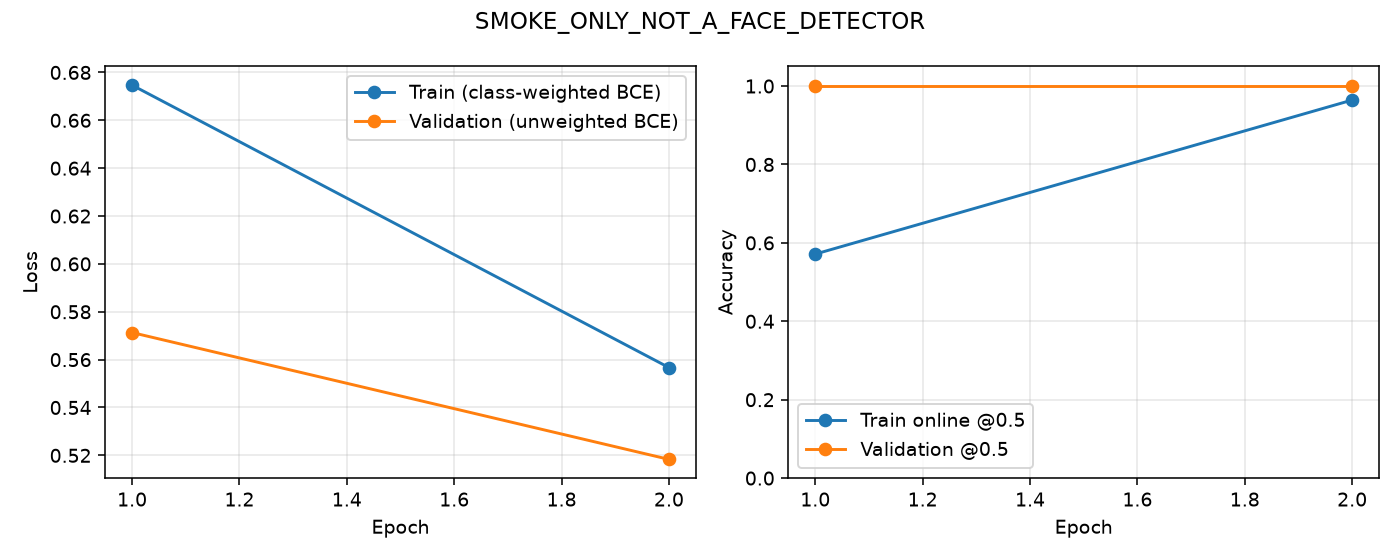

In [6]:
from facejpeg.train import train
BEST = train(PREPARED, RUN, epochs=EPOCHS, batch_size=BATCH_SIZE, quick=QUICK,
             resume=RESUME, workers=WORKERS, allow_cpu_real=ALLOW_CPU_REAL,
             warmup_epochs=1, finetune_blocks=3, use_amp=True)
display(pd.read_csv(RUN / "history.csv"))
display(DisplayImage(filename=str(RUN / "learning_curves.png")))
print("Measured timing:", (RUN / "timing.json").read_text())

## 7 — إعادة التحميل والتقييم الأساسي
تُحمّل الأوزان مرتين ونقارن درجة الصورة نفسها من التحقق. ثم نفتح الاختبار الأصلي فقط، دون تغيير النموذج أو الحدود. Precision/Recall/F1/Accuracy الثنائية عند0.5 مقاييس مساعدة مع zero_division=0؛ حكم الواجهة ثلاثي وله تغطية وغير حاسم ومقامات مستقلة. لا تُفسّر أرقام Quick على أنها نتائج وجوه.

In [7]:
from facejpeg.infer import Predictor
from facejpeg.common import read_rgb
from facejpeg.evaluate import evaluate
predictor = Predictor(BEST, "cpu" if QUICK else None)
_second = Predictor(BEST, "cpu" if QUICK else None)
_example = PREPARED / manifest.loc[manifest.split == "val", "path"].iloc[0]
assert abs(predictor.score(read_rgb(_example)) - _second.score(read_rgb(_example))) < 1e-7
del _second
baseline = evaluate(PREPARED, BEST, RUN / "baseline", device="cpu" if QUICK else None, qualities=["original"])
display(baseline[["quality","binary_accuracy_at_0_5_all","binary_precision_at_0_5","binary_recall_at_0_5","binary_f1_at_0_5","roc_auc_all"]])
print("ثبّتت الأوزان والحدود؛ لن نختارها من نتائج الاختبار التالية.")

21:10:12 | بدء المرحلة: تقييم الاختبار JPEG=original; total=6
Test Q=original: 100%|##########| 1/1 [00:00<00:00, 10.71batch/s]
21:10:12 | بدء المرحلة: حفظ الجداول والرسوم والتقرير; total=None
21:10:12 | اكتمل تقييم 6 صورة × 1 حالات؛ لم تُعدّل حدود التحقق
 quality  n_total  n_real  n_fake  fake_detected  fake_detection_rate_all_fake  real_falsely_accused  false_accusation_rate_all_real  abstain_real  abstain_fake  abstain_total  abstain_rate_all  coverage_all  selective_accuracy_accepted  precision_predicted_fake  fake_f1_with_abstention  binary_accuracy_at_0_5_all  binary_precision_at_0_5  binary_recall_at_0_5  binary_f1_at_0_5  binary_macro_f1_at_0_5  roc_auc_all
original        6       3       3              2                      0.666667                     0                             0.0             1             1              2          0.333333      0.666667                          1.0                       1.0                      0.8                         1.0           

,quality,binary_accuracy_at_0_5_all,binary_precision_at_0_5,binary_recall_at_0_5,binary_f1_at_0_5,roc_auc_all
0,original,1.0,1.0,1.0,1.0,1.0


## 8 — تجربة JPEG المستقلة والتقرير العربي
كل صورة اختبار في الأصل ثم100/90/70/50/30/10، مباشرة من الأصل الموحّد224×224؛ لا ضغط متسلسل ولا تسرب نسخ إلى التدريب. original ليس Q100؛ حتىQ100 إعادة ترميز خسِرة، وقد يكون الأصل مضغوطًا سابقًا. المقارنة تخص هذا البروتوكول عند224×224، لا الدقة الخام كاملة.

اكتشاف المولّد مقامه **كل المولّدات**؛ الاتهام الخاطئ مقامه **كل الفوتوغرافيات**؛ غير الحاسم مقامه **كل الاختبار**. مصفوفة2×3 تُظهره. تُحفظ ROC/AUC وF1 والتغير بالنقاط المئوية وأمثلة الأحكام المتبدلة إن وجدت، وتقرير عربي من الأرقام نفسها. عدم وجود مثال متغير يُذكر بدل اختلاقه.

21:10:12 | بدء المرحلة: تقييم الاختبار JPEG=original; total=6
Test Q=original: 100%|##########| 1/1 [00:00<00:00, 37.72batch/s]
21:10:12 | بدء المرحلة: تقييم الاختبار JPEG=100; total=6
Test Q=100: 100%|##########| 1/1 [00:00<00:00, 29.88batch/s]
21:10:12 | بدء المرحلة: تقييم الاختبار JPEG=90; total=6
Test Q=90: 100%|##########| 1/1 [00:00<00:00, 27.69batch/s]
21:10:12 | بدء المرحلة: تقييم الاختبار JPEG=70; total=6
Test Q=70: 100%|##########| 1/1 [00:00<00:00, 32.69batch/s]
21:10:12 | بدء المرحلة: تقييم الاختبار JPEG=50; total=6
Test Q=50: 100%|##########| 1/1 [00:00<00:00, 33.99batch/s]
21:10:13 | بدء المرحلة: تقييم الاختبار JPEG=30; total=6
Test Q=30: 100%|##########| 1/1 [00:00<00:00, 34.94batch/s]
21:10:13 | بدء المرحلة: تقييم الاختبار JPEG=10; total=6
Test Q=10: 100%|##########| 1/1 [00:00<00:00, 35.20batch/s]
21:10:13 | بدء المرحلة: حفظ الجداول والرسوم والتقرير; total=None
21:10:14 | اكتمل تقييم 6 صورة × 7 حالات؛ لم تُعدّل حدود التحقق
 quality  n_total  n_real  n_fake  fake_detect

,quality,n_total,n_real,n_fake,fake_detected,fake_detection_rate_all_fake,real_falsely_accused,false_accusation_rate_all_real,abstain_real,abstain_fake,abstain_total,abstain_rate_all,coverage_all,selective_accuracy_accepted,precision_predicted_fake,fake_f1_with_abstention,binary_accuracy_at_0_5_all,binary_precision_at_0_5,binary_recall_at_0_5,binary_f1_at_0_5,binary_macro_f1_at_0_5,roc_auc_all
0,original,6,3,3,2,0.666667,0,0.0,1,1,2,0.333333,0.666667,1.0,1.0,0.8,1.000000,1.00,1.0,1.000000,1.000000,1.0
1,100,6,3,3,2,0.666667,0,0.0,1,1,2,0.333333,0.666667,1.0,1.0,0.8,1.000000,1.00,1.0,1.000000,1.000000,1.0
2,90,6,3,3,2,0.666667,0,0.0,1,1,2,0.333333,0.666667,1.0,1.0,0.8,1.000000,1.00,1.0,1.000000,1.000000,1.0
3,70,6,3,3,2,0.666667,0,0.0,0,1,1,0.166667,0.833333,1.0,1.0,0.8,1.000000,1.00,1.0,1.000000,1.000000,1.0
4,50,6,3,3,2,0.666667,0,0.0,1,1,2,0.333333,0.666667,1.0,1.0,0.8,1.000000,1.00,1.0,1.000000,1.000000,1.0
5,30,6,3,3,1,0.333333,0,0.0,1,2,3,0.500000,0.500000,1.0,1.0,0.5,0.833333,0.75,1.0,0.857143,0.828571,1.0
6,10,6,3,3,0,0.000000,0,0.0,1,3,4,0.666667,0.333333,1.0,NaN,0.0,0.833333,0.75,1.0,0.857143,0.828571,1.0


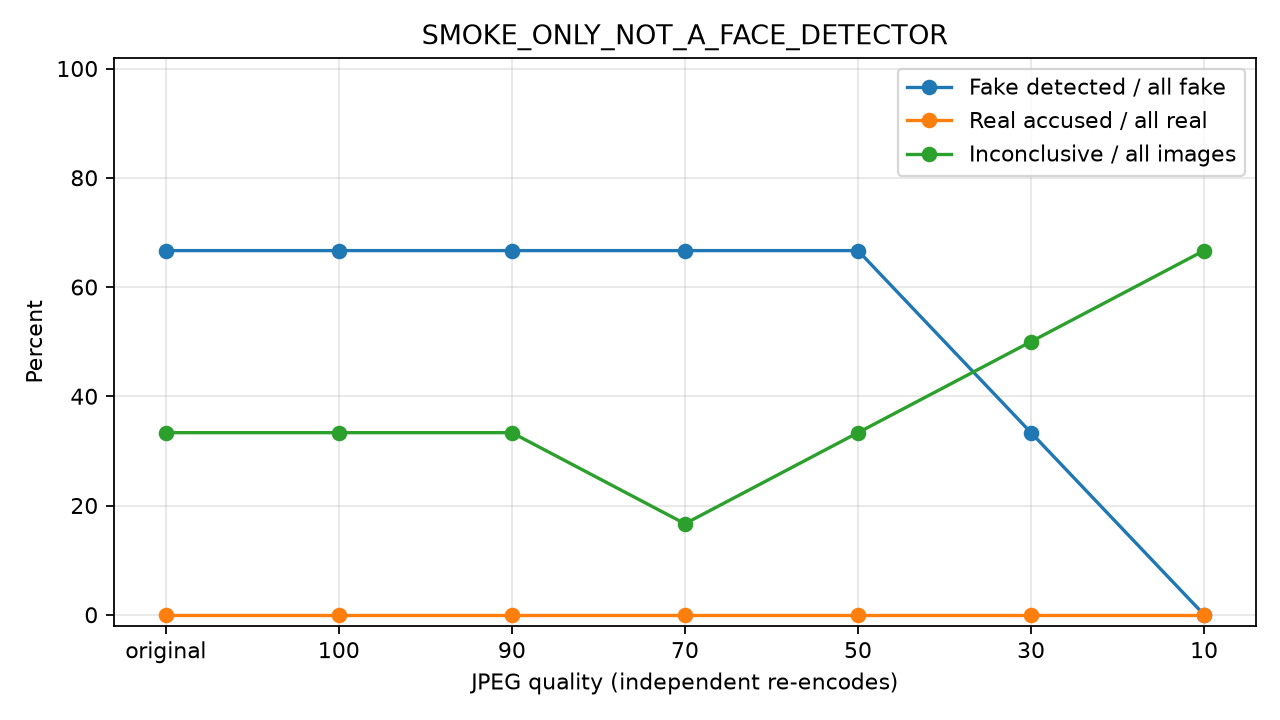

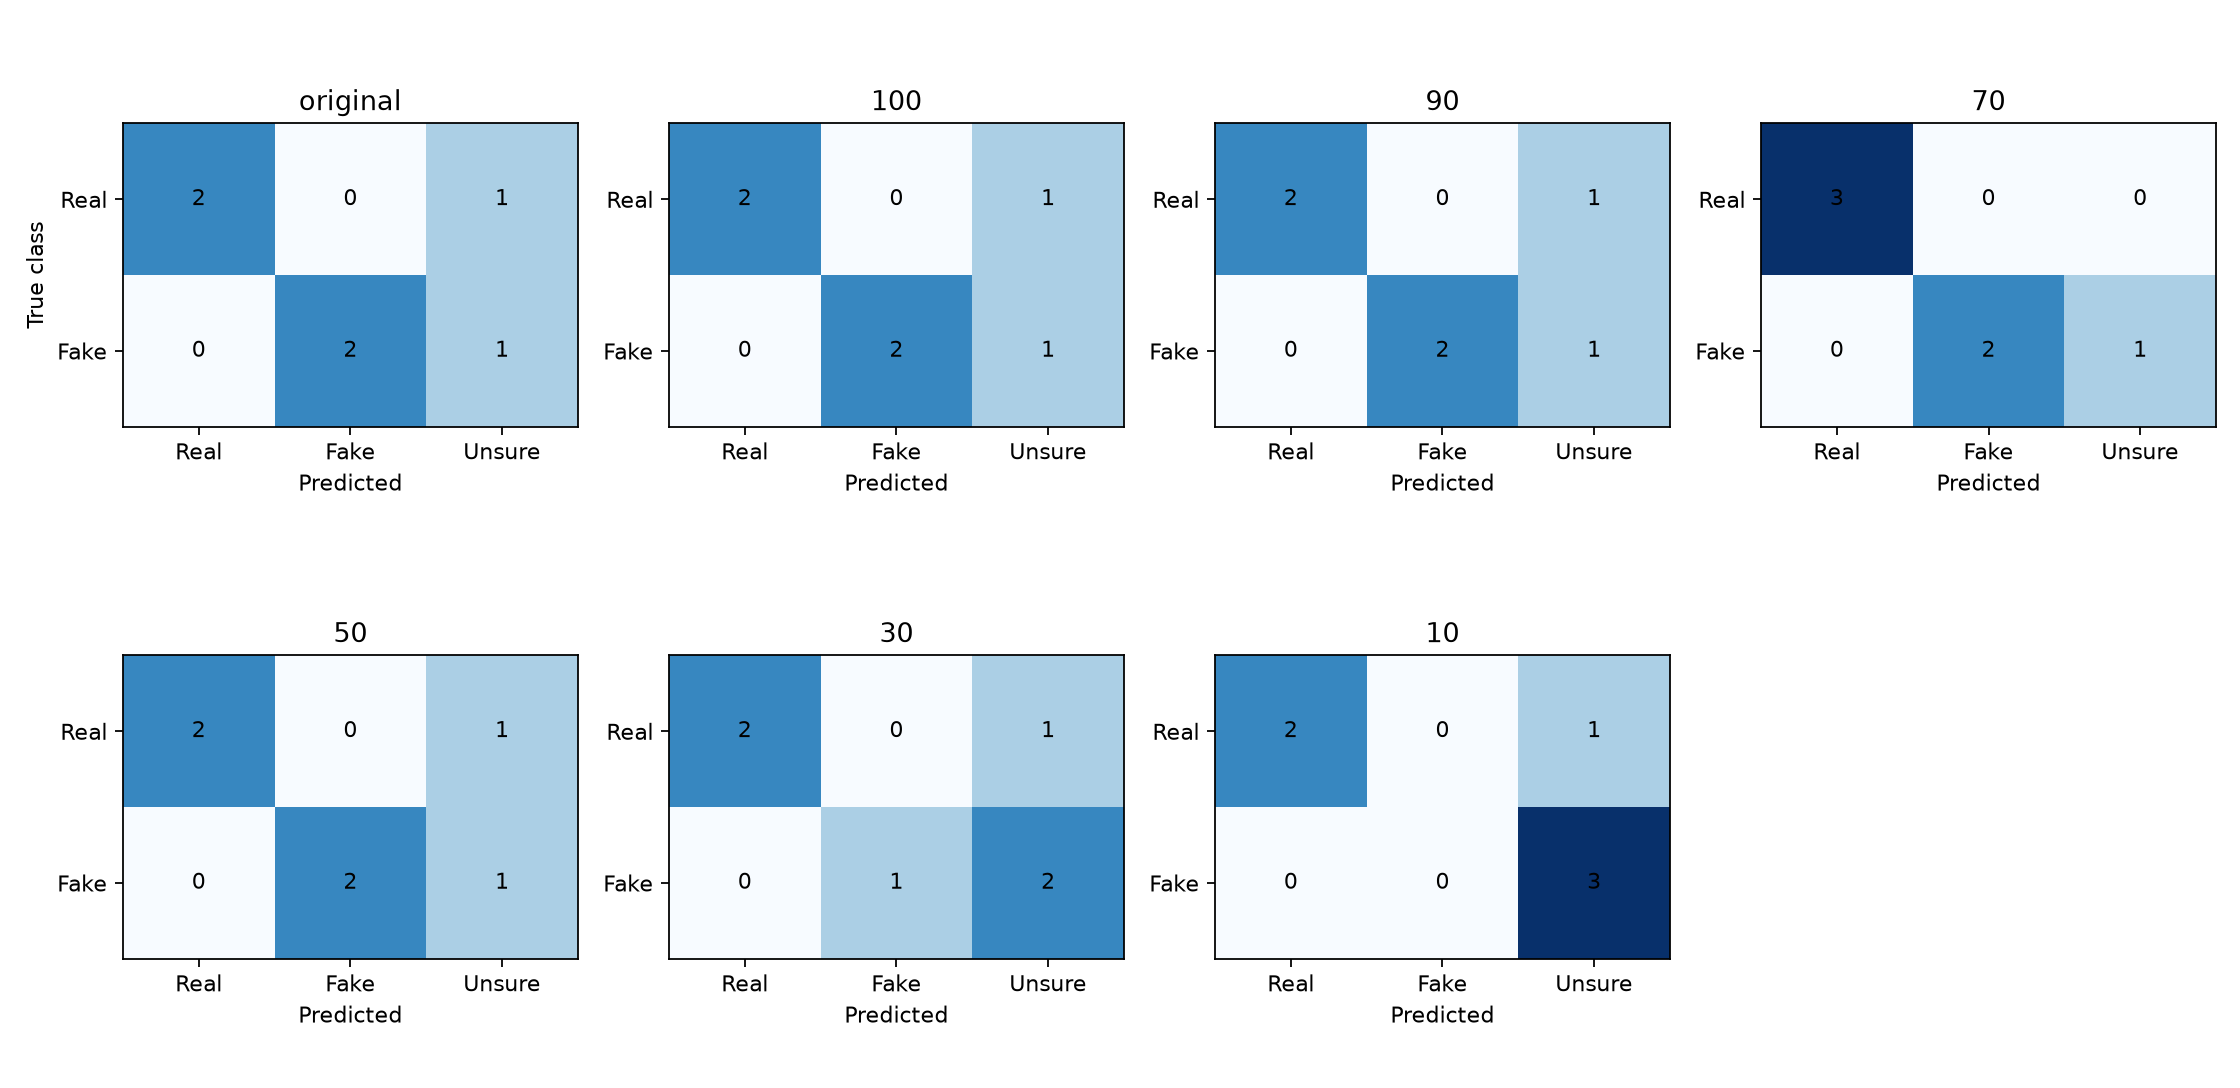

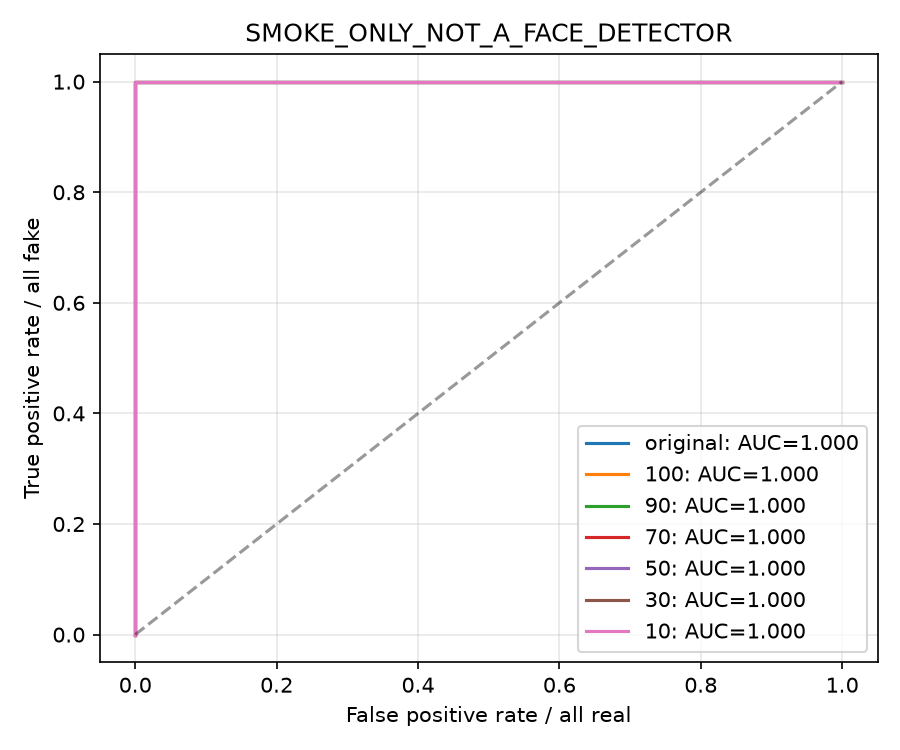

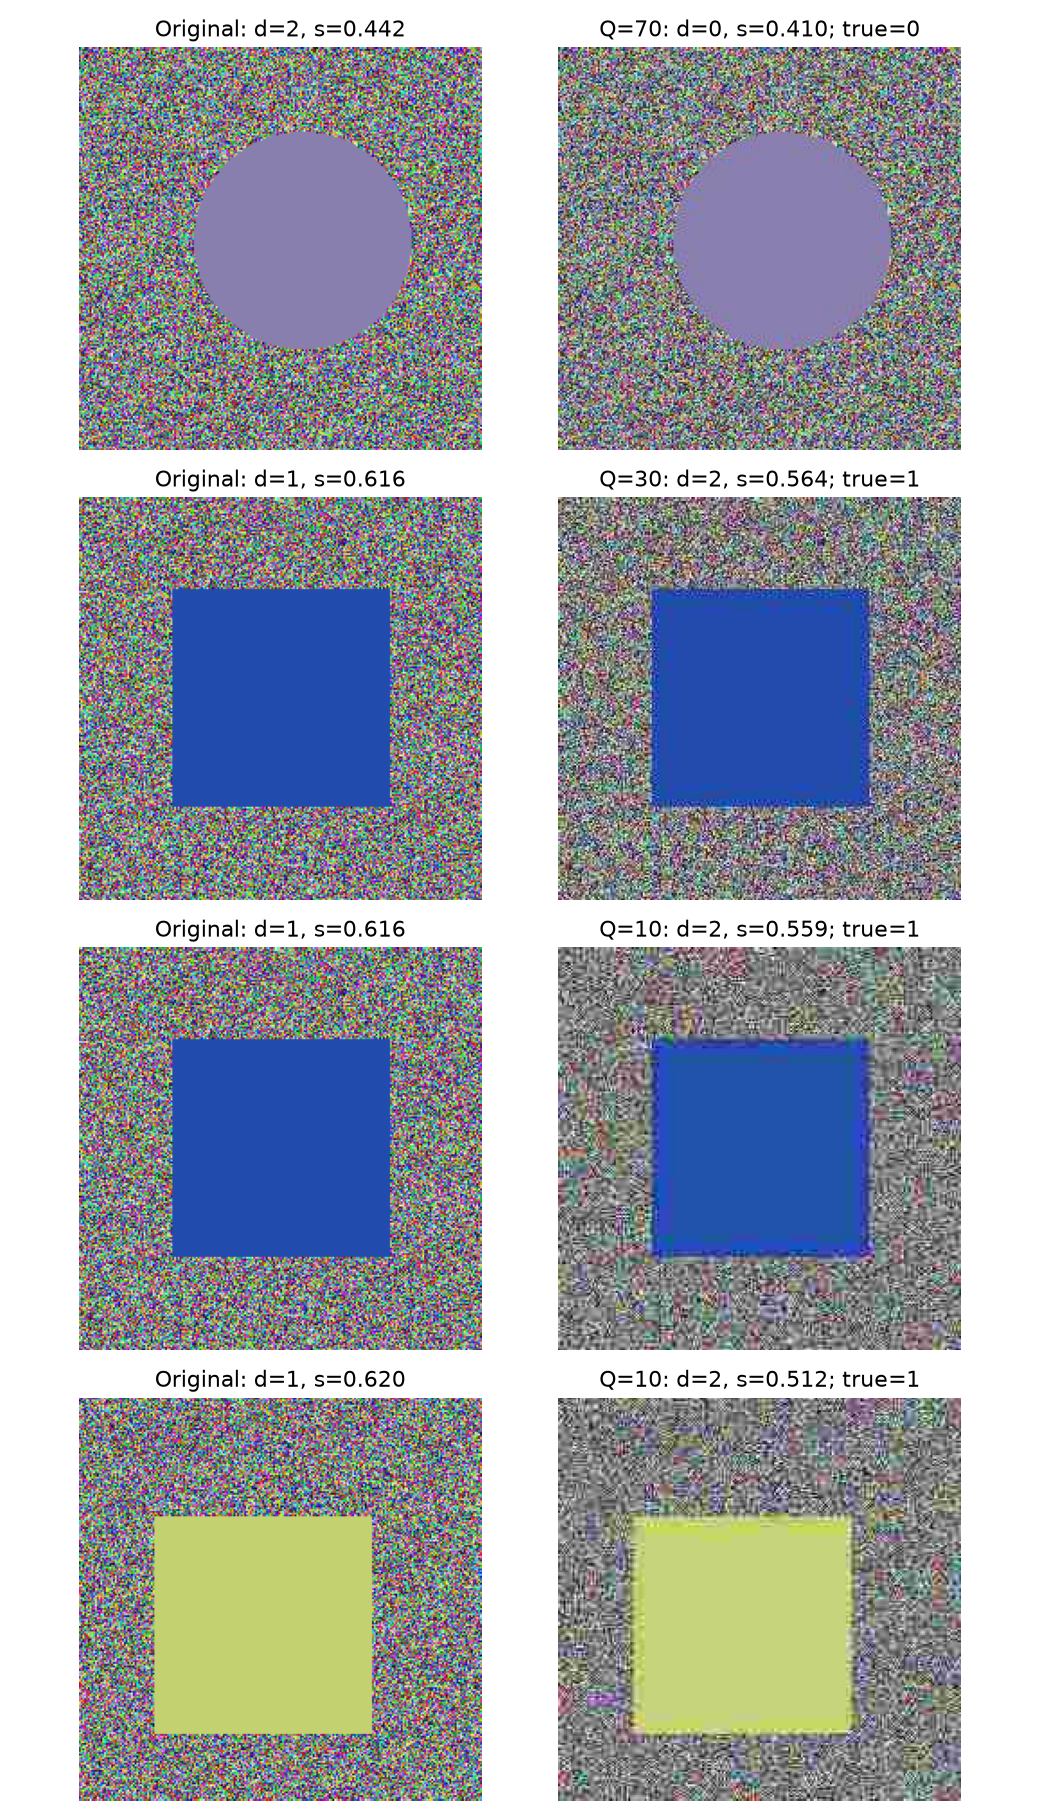

# تقرير تجربة JPEG — SMOKE_ONLY_NOT_A_FACE_DETECTOR

الدرجة ترجيح النموذج للفئة المولّدة، وليست إثباتًا للأصالة أو احتمالًا معايرًا.
خط الأساس original هو الأصل المفكوك بعد توحيد RGB والقص المركزي إلى 224×224، دون إعادة JPEG إضافية. كل جودة أُنشئت مستقلة منه، وليست سلسلة ضغط. قد يكون الأصل نفسه JPEG سابقًا.

نسبة اكتشاف المولّد = المولّد المحكوم عليه fake ÷ جميع المولّدات؛ الاتهام الخاطئ = الحقيقي المحكوم عليه fake ÷ جميع الصور الحقيقية. غير الحاسم يُعدّ ضمن المقام ولا يُحتسب اكتشافًا صحيحًا. الدقة الانتقائية مقامها الحالات المحسومة فقط؛ AUC تستخدم جميع الدرجات.

**هذه بيانات هندسية اصطناعية لاختبار البرمجيات فقط. لا تمثل صور أشخاص أو قدرة كشف التوليد. لا تُقدّم أرقامها كنتيجة علمية للمشروع.**

- الجودة original: اكتشف 2/3 مولّدة (66.7%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 2/6 (33.3%).
- الجودة 100: اكتشف 2/3 مولّدة (66.7%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 2/6 (33.3%).
- الجودة 90: اكتشف 2/3 مولّدة (66.7%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 2/6 (33.3%).
- الجودة 70: اكتشف 2/3 مولّدة (66.7%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 1/6 (16.7%).
- الجودة 50: اكتشف 2/3 مولّدة (66.7%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 2/6 (33.3%).
- الجودة 30: اكتشف 1/3 مولّدة (33.3%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 3/6 (50.0%).
- الجودة 10: اكتشف 0/3 مولّدة (0.0%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 4/6 (66.7%).

عند الجودة 10 تغيّر معدل اكتشاف المولّد بمقدار -66.7 نقطة مئوية، ومعدل الاتهام الخاطئ بمقدار +0.0 نقطة مقارنة بالأصل.
التصنيف الثنائي المساعد عند 0.5 على الأصل: Accuracy=1.0000، Precision=1.0000، Recall=1.0000، F1=1.0000، AUC=1.0000. هذه المقاييس لا تمثل قرار الواجهة الثلاثي؛ عمود fake_f1_with_abstention يحسب غير الحاسم المولّد ضمن ما لم يُكتشف. عند غياب توقعات موجبة نُعرّف Precision وF1 الثنائيين بصفر (zero_division=0).
هذه مقارنة زوجية على الصور نفسها. لا يلزم أن يكون الأثر رتيبًا مع الجودة، ولا يجوز تعميمه على مولّدات أخرى أو صور الإنترنت. لا يمكن بهذه التجربة وحدها فصل بصمات المولّد عن بصمات مصدر البيانات.
العينة الصغيرة والتكرارات القريبة غير المكتشفة وغياب بيانات الهوية تحدّ الاستنتاج. يُفضّل تكرار التجربة على مصدر خارجي ومولّد غير مستخدم في التدريب.

In [8]:
RESULTS = RUN / "evaluation"
table = evaluate(PREPARED, BEST, RESULTS, device="cpu" if QUICK else None)
display(table)
for _figure in ["jpeg_effect.png", "confusion_matrices.png", "roc_curves.png", "changed_examples.png"]:
    if (RESULTS / _figure).exists():
        display(DisplayImage(filename=str(RESULTS / _figure)))
display(Markdown((RESULTS / "REPORT_AR.md").read_text()))

## 9 — حفظ النموذج والتقارير وتنزيل النتائج
أفضل أوزان وlast.pt والسجلات محفوظة بالفعل في RUN؛ وفي Google Drive إن فُعّل USE_DRIVE. ZIP التالي يتضمنها مع ملفات التقسيم والتقارير؛ لا يتضمن صور التدريب افتراضيًا لتجنب انتظار ضغط آلاف الصور. **استكمال التدريب يحتاج صور prepared أيضًا**: احتفظ بمجلد Drive كاملًا أو اختر EXPORT_INCLUDE_PREPARED=True قبل التصدير. تنزيل ZIP يدويًا من لوحة Files لا يعطل Run all، ولا يُفتح مربع رفع جديد.

In [9]:
import zipfile
RESULT_ZIP = PROJECT / (EXPERIMENT + "_results.zip")
_export_files = [p for p in RUN.rglob("*") if p.is_file() and (EXPORT_INCLUDE_PREPARED or not p.is_relative_to(PREPARED / "images"))]
from tqdm.auto import tqdm
with zipfile.ZipFile(RESULT_ZIP, "w", zipfile.ZIP_DEFLATED) as _zip:
    for _p in tqdm(_export_files, desc="Export results", unit="file"):
        _zip.write(_p, _p.relative_to(RUN))
print("Results ZIP:", RESULT_ZIP)
print("Best checkpoint:", BEST)
print("Resume images included:", EXPORT_INCLUDE_PREPARED)

Export results: 100%|##########| 48/48 [00:00<00:00, 65.10file/s]
Results ZIP: /workspace/facejpeg-release-check/facejpeg_final_v2/quick_v2_results.zip
Best checkpoint: /workspace/facejpeg-release-check/facejpeg_final_v2/runs/quick_v2/best.pt
Resume images included: False


## 10 — واجهة Gradio العربية
ارفع JPG/PNG لوجه أمامي واحد واضح في المنتصف؛ سيُعرض الأصل الموحّد والنسخة المضغوطة ودرجات الفئتين والحكم الثلاثي. لا وجه/عدة وجوه/ملف تالف تظهر برسالة عربية. Haar بوابة بسيطة قد تخطئ. إن كانت الأوزان اختبارًا هندسيًا أو مفقودة تُعرض رسالة دائمة؛ درجات الفئات غير معايرة ولا تثبت الأصالة.

في Colab ينشئ SHARE_GRADIO رابطًا عامًا مؤقتًا؛ افتحه بعد تشغيل الخلية ولا ترفع صورًا حساسة. محليًا لا حاجة للمشاركة العامة: `python app.py --checkpoint /path/to/best.pt`. أغلق الواجهة بعد الانتهاء.

In [10]:
from app import create_app
if LAUNCH_UI:
    if "demo" in globals():
        demo.close()
    demo = create_app(BEST)
    demo.launch(share=SHARE_GRADIO if IN_COLAB else False, debug=False)
else:
    print("تشغيل الواجهة معطّل لهذا الفحص غير التفاعلي؛ شغّل create_app(BEST).launch() عند الحاجة.")

تشغيل الواجهة معطّل لهذا الفحص غير التفاعلي؛ شغّل create_app(BEST).launch() عند الحاجة.
